# Image Captioning with BLIP
### AI that describes what it sees in an image!
---
**Model:** Salesforce/blip-image-captioning-base

> **BLIP = Bootstrapping Language-Image Pre-training**
> You give it an image → it writes a sentence about it!

**Examples:**
- Photo of a dog → *'a dog running on the grass'*
- Photo of a city → *'a city street with cars and people'*
- Photo of food   → *'a bowl of rice with vegetables'*


---
## Step 1 — Install and load BLIP


In [ ]:
!pip install transformers gradio pillow -q

from transformers import BlipProcessor, BlipForConditionalGeneration
from transformers.utils import logging
import warnings
warnings.filterwarnings('ignore')
logging.set_verbosity_error()

print('Loading BLIP model...')
processor  = BlipProcessor.from_pretrained(
                 'Salesforce/blip-image-captioning-base')
blip_model = BlipForConditionalGeneration.from_pretrained(
                 'Salesforce/blip-image-captioning-base')
print('BLIP ready!')


Loading BLIP model...


preprocessor_config.json:   0%|          | 0.00/287 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/4.56k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/506 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

...

special_tokens_map.json:   0%|          | 0.00/125 [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  990MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/473 [00:00<?, ?it/s]

BLIP ready!


---
## Step 2 — Upload your own image

> Instead of downloading an image from a URL, upload a photo from your computer.
> In Google Colab, a file picker will open when you run the next cell.
> Supported formats include JPG, JPEG, and PNG.


Saving WhatsApp Image 2026-10-12 at 2.24.50 PM.jpeg to WhatsApp Image 2026-10-12 at 2.24.50 PM.jpeg


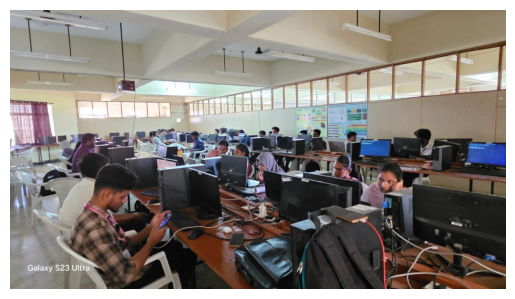

Image size: (1600, 900)


In [ ]:
from PIL import Image
import matplotlib.pyplot as plt

# Upload your own image (Google Colab)
try:
    from google.colab import files
    uploaded = files.upload()

    if not uploaded:
        raise ValueError("No image was uploaded. Run this cell again and choose an image.")

    image_filename = next(iter(uploaded))
    image = Image.open(image_filename).convert("RGB")

except ImportError:
    # If you are not using Google Colab, enter the path to your local image.
    image_path = input("Enter the path to your image file (for example, ./my_photo.jpg): ").strip()
    image = Image.open(image_path).convert("RGB")

# Display the uploaded image
plt.imshow(image)
plt.axis("off")
plt.show()

# Print image size
print("Image size:", image.size)


**Tip:** Run the previous cell and select your own image. The rest of the notebook will use that uploaded image.

---
## Step 3 — Create the caption function

> This function takes an image and returns a sentence.
> Same idea as the translate() and summarize() functions we built before!


In [ ]:
def get_caption(image):
    # Step A: prepare the image for BLIP
    inputs = processor(image.convert('RGB'), return_tensors='pt')

    # Step B: generate the caption
    with torch.no_grad():
        output = blip_model.generate(**inputs, max_new_tokens=50)

    # Step C: convert numbers back to text
    caption = processor.decode(output[0], skip_special_tokens=True)
    return caption

print('get_caption() function ready!')


get_caption() function ready!


---
## Step 4 — Generate your first caption!

> Look at the image above.
> Write what YOU think is in it.
> Then run this cell — see if BLIP agrees!


In [ ]:
import torch

caption = get_caption(image)

print("BLIP says:")
print(f'  "{caption}"')
print()
print(f"Word count: {len(caption.split())} words")

BLIP says:
  "a classroom with computers and people working on the computers"

Word count: 10 words


PyTorch (torch) is a Python library used to build, train, and run Artificial Intelligence (AI) and Machine Learning (ML) models.
In your BLIP image captioning project, torch helps the model process an image and generate a description of it.

---
## Step 5 — Guide the caption with a prompt

> You can give BLIP a starting phrase.
> It will complete the sentence from that starting point.

> Example: give it `'there are'` → it says `'there are three people standing'`


In [ ]:
def get_caption_with_prompt(image, prompt):
    # Same as before — but we add a starting text
    inputs = processor(image.convert('RGB'),
                       text   = prompt,
                       return_tensors = 'pt')
    with torch.no_grad():
        output = blip_model.generate(**inputs, max_new_tokens=50)
    return processor.decode(output[0], skip_special_tokens=True)


# Same image — different starting prompts
prompts = [
    'a photo of',
    'this image shows',
    'there are',
]

print('Same image — different prompts:')
print()
for prompt in prompts:
    result = get_caption_with_prompt(image, prompt)
    print(f'Prompt  : "{prompt}"')
    print(f'Caption : "{result}"')
    print()


Same image — different prompts:

Prompt  : "a photo of"
Caption : "a photo of a classroom with computers and people"

Prompt  : "this image shows"
Caption : "this image shows a classroom in the university of guli, in guli district, in guli district, in guli district, in"

Prompt  : "there are"
Caption : "there are many people working in the office"



---
## Step 7 — How does max_new_tokens affect the caption?

> More tokens = longer caption.
> Let's see the difference!


In [ ]:
import pandas as pd

token_lengths = [20, 40, 60, 80]
results = []

for max_t in token_lengths:
    inputs = processor(image.convert('RGB'), return_tensors='pt')
    with torch.no_grad():
        output = blip_model.generate(**inputs, max_new_tokens=max_t)
    cap   = processor.decode(output[0], skip_special_tokens=True)
    words = len(cap.split())
    results.append({'max_tokens': max_t, 'words': words, 'caption': cap})
    print(f'max_tokens={max_t:3d} → {words} words: {cap}')

print()
print('More tokens = longer caption')
print('But after a point the caption does not grow much more')


max_tokens= 20 → 10 words: a classroom with computers and people working on the computers
max_tokens= 40 → 10 words: a classroom with computers and people working on the computers
max_tokens= 60 → 10 words: a classroom with computers and people working on the computers
max_tokens= 80 → 10 words: a classroom with computers and people working on the computers

More tokens = longer caption
But after a point the caption does not grow much more


## MULTIPLE IMAGES

In [ ]:
from PIL import Image
import matplotlib.pyplot as plt

# Upload multiple images from your computer (Google Colab)
try:
    from google.colab import files
    uploaded_images = files.upload()

    if not uploaded_images:
        print("No images uploaded. Run this cell again and select one or more images.")
    else:
        for filename in uploaded_images:
            try:
                # Open each uploaded image
                img = Image.open(filename).convert("RGB")

                # Generate caption using BLIP
                caption = get_caption(img)

                # Display image and caption
                plt.imshow(img)
                plt.axis("off")
                plt.title(caption, wrap=True)
                plt.show()

                print("Image:", filename)
                print("Caption:", caption)
                print()
            except Exception as e:
                print(f"Could not process {filename}: {e}")

except ImportError:
    print("Multiple-image upload is available in Google Colab. For other notebook environments, use Step 2 to load an image.")


The multiple-image cell lets you choose image files from your computer.

- `files.upload()` opens a file picker in Google Colab.
- `Image.open(filename)` opens each uploaded image.
- `.convert("RGB")` ensures the image uses the standard three color channels.
- `get_caption(img)` generates a description using the same BLIP model.

The Gradio app in Step 8 already supports uploading an image directly, so its functionality remains the same.

---
## Step 8 — Build a Gradio Caption App

> Upload ANY photo from your phone.
> Choose an optional starting prompt.
> AI writes the caption instantly!


In [ ]:
import gradio as gr

def caption_app(uploaded_image, prompt):
    if uploaded_image is None:
        return 'Please upload an image first!'

    img = uploaded_image.convert('RGB')

    # Use prompt if given, otherwise plain caption
    if prompt.strip():
        caption = get_caption_with_prompt(img, prompt)
    else:
        caption = get_caption(img)

    word_count = len(caption.split())
    return f'Caption:\n"{caption}"\n\nWords: {word_count}'


app = gr.Interface(
    fn      = caption_app,
    inputs  = [
        gr.Image(
            type  = 'pil',
            label = 'Upload any image'
        ),
        gr.Textbox(
            label       = 'Starting prompt (optional)',
            placeholder = 'Example: a photo of    OR leave empty',
            lines       = 1
        )
    ],
    outputs     = gr.Textbox(label='AI Caption', lines=4),
    title       = 'Image Captioning — BLIP',
    description = 'Upload any image — AI writes a sentence about it!'
)

app.launch(share=True)


Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://53f18965902f57507b.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [ ]:
app.close()
print('App closed.')
